### Antenna dataset creation

In [ ]:
import os
import glob
import urllib.request
import pandas as pd
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm

# --- CONFIGURATION ---
# Points to your raw data directory
DATA_DIR = "../data/antenna_raw_data"
# We can output the images and consolidated CSV in the parent 'data' folder
PARENT_DATA_DIR = os.path.dirname(DATA_DIR)
IMAGES_OUT_DIR = os.path.join(PARENT_DATA_DIR, "antenna_field_images")
CONSOLIDATED_CSV = os.path.join(PARENT_DATA_DIR, "antenna_processed_dataset.csv")

# Create output directories if they don't exist
os.makedirs(IMAGES_OUT_DIR, exist_ok=True)

# 1. Dynamically scan the folder for ALL CSV files
csv_pattern = os.path.join(DATA_DIR, "*.csv")
csv_files = glob.glob(csv_pattern)

# Prevent loading our own output tracking CSV if it's placed in the same folder
csv_files = [f for f in csv_files if os.path.abspath(f) != os.path.abspath(CONSOLIDATED_CSV)]

print(f"🔍 Scanning directory: {DATA_DIR}")
if not csv_files:
    raise FileNotFoundError(f"❌ No CSV files found in {DATA_DIR}. Please check the folder path!")
else:
    print(f"✔ Found {len(csv_files)} CSV files to process:")
    for f in csv_files:
        print(f"  - {os.path.basename(f)}")

# 2. Combine and read all discovered CSV files
df_list = []
for file in csv_files:
    try:
        # FIXED: Use encoding_errors='ignore' to handle encoding anomalies safely
        df_temp = pd.read_csv(file, encoding="utf-8", encoding_errors="ignore")
        df_list.append(df_temp)
    except Exception as e:
        print(f"❌ Error reading {os.path.basename(file)}: {e}")

if not df_list:
    raise ValueError("No data could be loaded from the CSV files.")

df_all = pd.concat(df_list, ignore_index=True)
print(f"\nMerged database shape: {len(df_all)} total raw rows across all files.")

# 3. Filter Records (Keep high-confidence biological observations)
exclude_classes = ["Not Lepidoptera", "Not Identifiable", "Unknown", "Not_Lepidoptera"]
df_filtered = df_all[
    (df_all["verification_status"].isin([True, "Verified"])) & 
    (~df_all["determination_name"].isin(exclude_classes)) &
    (df_all["best_detection_url"].notna())
].copy()

print(f"Filtered down to {len(df_filtered)} high-confidence insect observations.")

# 4. Extract target columns
df_extracted = pd.DataFrame({
    'individual_id': df_filtered['id'],
    'species': df_filtered['determination_name'],
    'location': df_filtered['deployment_name'],
    'pixel_width': df_filtered['best_detection_width'],
    'pixel_height': df_filtered['best_detection_height'],
    'image_url': df_filtered['best_detection_url']
}).drop_duplicates(subset=['individual_id'])

# Create local relative file paths for each downloaded image
df_extracted['local_image_path'] = df_extracted.apply(
    lambda row: os.path.join("antenna_field_images", f"ind_{int(row['individual_id'])}.jpg"), axis=1
)

# 5. Downloader Function
def download_image(row):
    url = row['image_url']
    dest = os.path.join(PARENT_DATA_DIR, row['local_image_path'])
    
    # Avoid duplicate downloads if we re-run the script
    if os.path.exists(dest):
        return True
        
    try:
        # Simple User-Agent header so the cloud server allows the script to fetch the file
        req = urllib.request.Request(
            url, 
            headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
        )
        with urllib.request.urlopen(req, timeout=10) as response, open(dest, 'wb') as out_file:
            out_file.write(response.read())
        return True
    except Exception as e:
        return f"Error downloading ID {row['individual_id']}: {e}"

# 6. Run Batch Download in Parallel Threads
print(f"\n🚀 Downloading {len(df_extracted)} insect crop images to '{IMAGES_OUT_DIR}'...")
records_dict = df_extracted.to_dict(orient='records')

results = []
with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(executor.map(download_image, records_dict), total=len(records_dict)))

failed_downloads = [r for r in results if r is not True]
print(f"\n✨ Download sequence finished.")
print(f"  - Successfully verified/downloaded: {len(records_dict) - len(failed_downloads)} crops")
if failed_downloads:
    print(f"  - Failed downloads: {len(failed_downloads)} (These URLs might be offline/slow)")

# 7. Save our clean database to disk
df_extracted.to_csv(CONSOLIDATED_CSV, index=False)
print(f"✔ Saved processed dataset tracking index to: {CONSOLIDATED_CSV}")

🔍 Scanning directory: /home/alexis/Documents/projets/antenna/data/antenna_raw_data
✔ Found 3 CSV files to process:
  - barro-colorado-island-research-station_export-97.csv
  - insectarium-de-montreal_export-103.csv
  - insectarium-de-montreal_export-72.csv

Merged database shape: 10860 total raw rows across all files.
Filtered down to 5747 high-confidence insect observations.

🚀 Downloading 5747 insect crop images to '/home/alexis/Documents/projets/antenna/data/antenna_field_images'...


100%|██████████| 5747/5747 [04:50<00:00, 19.80it/s] 


✨ Download sequence finished.
  - Successfully verified/downloaded: 5747 crops
✔ Saved processed dataset tracking index to: /home/alexis/Documents/projets/antenna/data/antenna_processed_dataset.csv


### Annotation stats

This shows a exemple of a mask we created

✔ Found 125 completed annotations.

Image: ind_10072.jpg
Dimensions: 148x132 pixels
Contains 1 segmented shapes:
  Shape 1: Label='full-body' | Type='polygon' | Vertices=113


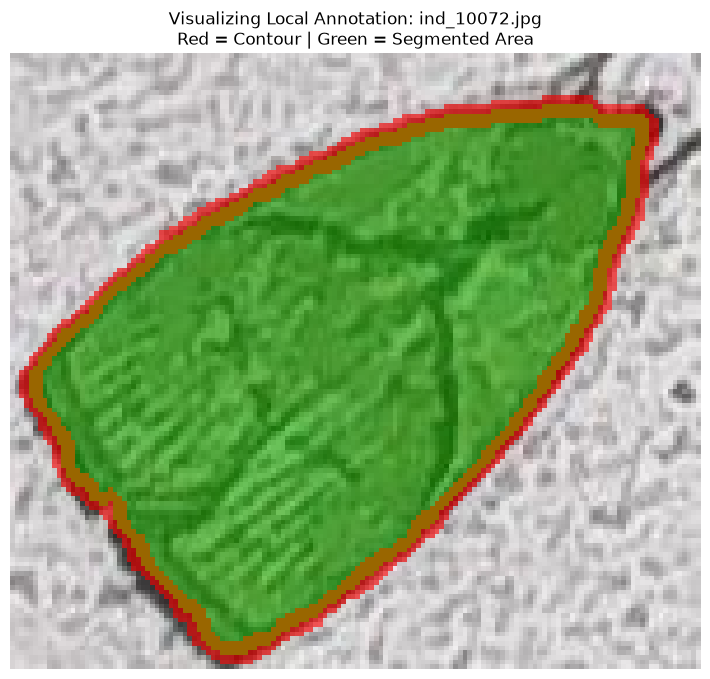

In [ ]:
import os
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- CONFIGURATION ---
DATA_DIR = "../data"
IMAGES_DIR = os.path.join(DATA_DIR, "antenna_field_images")

# 1. Grab all labeled JSON files in your directory
json_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.json')]

if not json_files:
    print("⚠ No annotated JSON files found yet. Make sure you saved at least one image in X-AnyLabeling!")
else:
    print(f"✔ Found {len(json_files)} completed annotations.")
    
    # Let's read the very first annotated image
    sample_json_name = json_files[0]
    json_path = os.path.join(IMAGES_DIR, sample_json_name)
    
    # 2. Load and parse the JSON file
    with open(json_path, 'r', encoding='utf-8') as f:
        annotation_data = json.load(f)
        
    # Match the corresponding image filename
    # Typically, the JSON has an "imagePath" key, or we just change the extension of our JSON file
    image_name = annotation_data.get("imagePath", sample_json_name.replace(".json", ".jpg"))
    img_path = os.path.join(IMAGES_DIR, image_name)
    
    # Load the image using OpenCV
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        # Fallback check if it was saved with a different extension
        img_path_fallback = os.path.join(IMAGES_DIR, sample_json_name.replace(".json", ".png"))
        img_bgr = cv2.imread(img_path_fallback)
        
    if img_bgr is None:
         raise FileNotFoundError(f"Could not load matching image for {sample_json_name}")
         
    # Convert to RGB for Matplotlib visualization
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    overlay = img_rgb.copy()
    
    # 3. Parse and draw every shape (polygon) found in the JSON
    shapes = annotation_data.get("shapes", [])
    print(f"\nImage: {image_name}")
    print(f"Dimensions: {annotation_data.get('imageWidth')}x{annotation_data.get('imageHeight')} pixels")
    print(f"Contains {len(shapes)} segmented shapes:")
    
    for i, shape in enumerate(shapes):
        label = shape.get("label", "unknown")
        points = shape.get("points", []) # List of [x, y] coordinates
        shape_type = shape.get("shape_type", "polygon")
        
        print(f"  Shape {i+1}: Label='{label}' | Type='{shape_type}' | Vertices={len(points)}")
        
        # Convert list of coordinate pairs to a NumPy array of integers
        pts = np.array(points, dtype=np.int32)
        
        if shape_type == "polygon":
            # Draw a semi-transparent solid fill inside the polygon
            cv2.fillPoly(overlay, [pts], color=(0, 255, 0)) # Translucent Green
            # Draw a solid outer contour line
            cv2.polylines(img_rgb, [pts], isClosed=True, color=(255, 0, 0), thickness=3) # Bright Red border
            
        elif shape_type == "rectangle":
            # If a simple bounding box was drawn
            pt1, pt2 = pts[0], pts[1]
            cv2.rectangle(img_rgb, tuple(pt1), tuple(pt2), color=(0, 0, 255), thickness=3)
            
    # Blend the original image with the semi-transparent mask fill (alpha blending)
    alpha = 0.4
    final_img = cv2.addWeighted(overlay, alpha, img_rgb, 1 - alpha, 0)
    
    # 4. Plot the final image in your notebook
    plt.figure(figsize=(10, 8))
    plt.imshow(final_img)
    plt.title(f"Visualizing Local Annotation: {image_name}\nRed = Contour | Green = Segmented Area")
    plt.axis("off")
    plt.show()

This snippet is for checking how many of each label categories we have tagged already.

In [4]:
import os
import json
from collections import Counter
import pandas as pd

# --- CONFIGURATION ---
DATA_DIR = "/home/alexis/Documents/projets/antenna/data"
IMAGES_DIR = os.path.join(DATA_DIR, "antenna_field_images")

# 1. Gather all JSON files
json_files = [f for f in os.listdir(IMAGES_DIR) if f.endswith('.json')]

if not json_files:
    print("⚠ No annotated JSON files found. Double-check your path!")
else:
    print(f"📊 Analyzing {len(json_files)} JSON annotations...")
    
    all_labels = []
    file_summary = []
    
    # 2. Parse each JSON file to extract labels and shapes
    for file_name in json_files:
        path = os.path.join(IMAGES_DIR, file_name)
        with open(path, 'r', encoding='utf-8') as f:
            try:
                data = json.load(f)
            except Exception as e:
                print(f"❌ Error reading {file_name}: {e}")
                continue
                
        shapes = data.get("shapes", [])
        labels_in_file = [shape.get("label") for shape in shapes]
        all_labels.extend(labels_in_file)
        
        # Keep track of what each file contains
        file_summary.append({
            "filename": file_name,
            "shape_count": len(shapes),
            "labels": list(set(labels_in_file))
        })

    # 3. Print overall class distribution
    print("\n" + "="*40)
    print("      🏷️  OVERALL LABEL DISTRIBUTION")
    print("="*40)
    label_counts = Counter(all_labels)
    for label, count in label_counts.items():
        print(f"  • {label:<15} : {count} instances")
    print("="*40)
    
    # 4. Turn summary into a clean Pandas DataFrame for deeper check
    df_summary = pd.DataFrame(file_summary)
    
    # Let's see what combinations of labels you have tagged per image
    df_summary['labels_str'] = df_summary['labels'].apply(lambda x: ", ".join(sorted(x)) if x else "[EMPTY]")
    combination_counts = df_summary['labels_str'].value_counts()
    
    print("\n" + "="*40)
    print("   🧩 ANATOMICAL COMBINATIONS PER IMAGE")
    print("="*40)
    for combo, count in combination_counts.items():
        print(f"  • {count:<4} images contain: {combo}")
    print("="*40)

📊 Analyzing 177 JSON annotations...

      🏷️  OVERALL LABEL DISTRIBUTION
  • full-body       : 160 instances
  • antenna         : 49 instances
  • leg             : 73 instances
  • head            : 45 instances
  • wing            : 91 instances
  • body            : 37 instances
  • abdomen         : 5 instances
  • torso           : 3 instances

   🧩 ANATOMICAL COMBINATIONS PER IMAGE
  • 122  images contain: full-body
  • 8    images contain: antenna, body, full-body, head, leg, wing
  • 7    images contain: antenna, body, head, leg, wing
  • 5    images contain: antenna, body, head, wing
  • 4    images contain: [EMPTY]
  • 4    images contain: body, head, leg, wing
  • 3    images contain: body, full-body, head, wing
  • 3    images contain: body, head, wing
  • 2    images contain: body, full-body, head, leg, wing
  • 2    images contain: full-body, head, wing
  • 1    images contain: full-body, head, leg, wing
  • 1    images contain: abdomen, antenna, head, leg, wing
  • 1  